# 02 · Data cleaning

Turns the delivered file into the firm-years used for modelling, following the findings of `01_eda.ipynb`.
Every step is row-wise, with fixed rules and no statistics learned from the data, so it can run before any train/test split
without leaking information. The checks are assert cells: if a rule or a count changes, the notebook stops.

Outputs:
- `data/processed/firm_years_clean.csv`: 2,028 firm-years, 592 companies, all sectors (Finance included).
- `data/processed/firm_years_naive.csv`: the same with the duplicates kept, for the naive leakage baseline only.
- `data/processed/schema.json`: the input lists (ratios, statement features, flags, bands) that `03_modelling.ipynb` reads, so they are defined once.
- `results/cleaning_numbers.json`: the counts quoted below.
- `figures/slides/flags.png`: the flags drawn for the presentation (section 6), in the deck style of `01_eda.ipynb`, section 15.
- `figures/slides/ratio_repairs.png`: what happened to each ratio that needed repair (section 7), same style.
- `figures/slides/misleading_values.png`: the two misleading values that are blanked and flagged (section 8), same style.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data/corporate_ratings_for_candidates_new.csv")
PROCESSED, RES, SLIDES = Path("../data/processed"), Path("../results"), Path("../figures/slides")

IG_GRADES = ["AAA", "AA", "A", "BBB"]
LETTERS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "CC", "C", "D"]          # best to worst
BANDS = ["AA and above", "A", "BBB", "BB", "B", "CCC and below"]
BAND_OF = {"AAA": 0, "AA": 0, "A": 1, "BBB": 2, "BB": 3, "B": 4, "CCC": 5, "CC": 5, "C": 5, "D": 5}

MARKET_PER_SHARE = ["enterpriseValueMultiple", "operatingCashFlowPerShare", "freeCashFlowPerShare"]
RATIOS = [                                                  # cashPerShare dropped: 55% missing, at random (01, section 8)
    "currentRatio", "quickRatio", "cashRatio", "daysOfSalesOutstanding",
    "netProfitMargin", "pretaxProfitMargin", "grossProfitMargin", "operatingProfitMargin",
    "returnOnAssets", "returnOnCapitalEmployed", "returnOnEquity", "assetTurnover",
    "fixedAssetTurnover", "debtEquityRatio", "debtRatio", "effectiveTaxRate",
    "freeCashFlowOperatingCashFlowRatio", "freeCashFlowPerShare", "companyEquityMultiplier",
    "ebitPerRevenue", "enterpriseValueMultiple", "operatingCashFlowPerShare",
    "operatingCashFlowSalesRatio", "payablesTurnover",
]
FEATURES = [c for c in RATIOS if c not in MARKET_PER_SHARE]      # 21 statement ratios an unrated firm has
FLAGS = ["roe_negative", "negative_equity", "ocf_negative", "cogs_not_reported", "payables_zero", "dso_zero"]

TOL = 1.001             # rounding slack for the liquidity-ratio ordering checks
NUMBERS = {}            # counts of record for this notebook

## 1. Load, remove duplicates and the corrupt row, fix impossible liquidity values
Duplicates are whole-row copies (01, section 2). The corrupt firm-year has every ratio scaled by about 10⁶ (01, section 3).
Quick assets are part of current assets and cash is part of quick assets, so a quick ratio above the current ratio,
or a cash ratio above either, is set missing; the rest of the row is kept (01, section 9).

In [2]:
def load_raw(path=DATA):
    """Read the file as delivered, with Date parsed."""
    df = pd.read_csv(path)
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    return df


def is_corrupt(df):
    """True for rows whose typical ratio is in the tens of thousands."""
    return df[RATIOS].abs().median(axis=1) > 1e4


def clean(df, dedupe=True):
    """Drop duplicates (unless dedupe=False) and corrupt rows, blank impossible liquidity ratios, add year."""
    df = df.copy()
    if dedupe:
        df = df.drop_duplicates()
    df = df[~is_corrupt(df)]

    bad_quick = df.quickRatio > df.currentRatio * TOL
    bad_cash = (df.cashRatio > df.currentRatio * TOL) | (~bad_quick & (df.cashRatio > df.quickRatio * TOL))
    df.loc[bad_quick, "quickRatio"] = np.nan
    df.loc[bad_cash, "cashRatio"] = np.nan

    df["year"] = df.Date.dt.year
    return df.reset_index(drop=True)

## 2. Rebuild censored values, add flags and the target
- **Equity multiplier** (assets ÷ equity): the reported value, else the balance-sheet identity 1 ÷ (1 − debt ratio), else ROE ÷ ROA.
  Where equity is within 2% of assets of zero the identity is sensitive to rounding, so ROE ÷ ROA is tried first and the identity, as computed, is the last resort: an extreme value that winsorising in 03 caps, never a median. Equity of exactly zero has no multiplier and counts as negative equity.
- **Negative equity** follows the equity multiplier (01, section 10).
- **ROE** was removed wherever it was negative (01, section 8). It is rebuilt with DuPont (net margin × asset turnover × equity multiplier),
  or set to −100% when that is impossible, and flagged `roe_negative`. When equity is negative ROE has no meaning, so it is set missing.
- **Suspected artefacts** (01, section 12): gross margin ≥ 0.99 means cost of goods sold was not reported; FCF/OCF is misleading when operating cash flow
  is negative; zero payables turnover and zero days sales outstanding are placeholders. Each gets a flag.
- **Target:** `SG` = 1 for BB and below; `band` groups the letters into 6 bands.

In [3]:
def engineer(df):
    """Rebuild the equity multiplier and censored ROE, add the flags, the target and the band (row-wise only)."""
    X = df.copy()
    reported_cem = X.companyEquityMultiplier
    roe_censored = X.returnOnEquity.isna()

    gap = 1 - X.debtRatio
    identity = 1 / gap.where(gap != 0)                                         # no multiplier when equity is exactly 0
    roe_over_roa = (X.returnOnEquity / X.returnOnAssets).where(X.returnOnAssets.abs() > 1e-3)
    X["companyEquityMultiplier"] = (reported_cem.fillna(identity.where(gap.abs() > 0.02))
                                    .fillna(roe_over_roa).fillna(identity))      # near zero: identity last, as computed

    negative_equity = (X.companyEquityMultiplier < 0) | (X.companyEquityMultiplier.isna() & (gap == 0))   # equity exactly 0 counts as negative
    X["negative_equity"] = negative_equity.astype(int)

    dupont = X.netProfitMargin * X.assetTurnover * X.companyEquityMultiplier
    X["returnOnEquity"] = X.returnOnEquity.fillna(dupont)
    X.loc[roe_censored & X.returnOnEquity.isna(), "returnOnEquity"] = -1.0       # censored, so negative
    X["roe_negative"] = (roe_censored | (X.returnOnEquity < 0) | (negative_equity & (X.netProfitMargin < 0))).astype(int)
    X.loc[negative_equity, "returnOnEquity"] = np.nan

    X["cogs_not_reported"] = (X.grossProfitMargin >= 0.99).astype(int)
    X.loc[X.cogs_not_reported == 1, "grossProfitMargin"] = np.nan
    X["ocf_negative"] = (X.operatingCashFlowSalesRatio < 0).astype(int)
    X.loc[X.ocf_negative == 1, "freeCashFlowOperatingCashFlowRatio"] = np.nan
    X["payables_zero"] = (X.payablesTurnover == 0).astype(int)
    X["dso_zero"] = (X.daysOfSalesOutstanding == 0).astype(int)

    X["IG"] = X.Rating.isin(IG_GRADES).astype(int)
    X["SG"] = 1 - X.IG
    X["letter_idx"] = X.Rating.map({r: i for i, r in enumerate(LETTERS)})
    X["band_idx"] = X.Rating.map(BAND_OF)
    X["band"] = X.band_idx.map(dict(enumerate(BANDS)))
    return X

## 3. Checks on the rules
Each rule is run on a made-up firm-year where the right answer is known.

In [4]:
def firm_year(**overrides):
    """One plausible BBB firm-year; keyword arguments override single fields."""
    row = dict.fromkeys(RATIOS, 1.0)
    row.update({"Rating": "BBB", "Name": "Test Co", "Rating Agency Name": "Agency", "Sector": "Energy",
                "Date": pd.Timestamp("2015-12-31"), "currentRatio": 2.0, "quickRatio": 1.5, "cashRatio": 0.5,
                "debtRatio": 0.6, "companyEquityMultiplier": 2.5, "netProfitMargin": 0.1, "assetTurnover": 0.8,
                "returnOnAssets": 0.08, "returnOnEquity": 0.2, "grossProfitMargin": 0.4,
                "operatingCashFlowSalesRatio": 0.15, "payablesTurnover": 6.0, "daysOfSalesOutstanding": 45.0})
    row.update(overrides)
    return row


def run(*rows):
    """Clean and engineer made-up firm-years."""
    return engineer(clean(pd.DataFrame(list(rows))))

In [5]:
# Liquidity ordering: cash <= quick <= current
out = run(firm_year(currentRatio=1.0, quickRatio=1.2, cashRatio=0.3),     # quick > current
          firm_year(currentRatio=2.0, quickRatio=0.5, cashRatio=0.8),     # cash > quick
          firm_year(currentRatio=1.0, quickRatio=1.2, cashRatio=1.1),     # both above current
          firm_year(currentRatio=1.0, quickRatio=1.0005, cashRatio=1.0))  # within the rounding slack
assert out.quickRatio.isna().tolist() == [True, False, True, False]
assert out.cashRatio.isna().tolist() == [False, True, True, False]

In [6]:
# Equity multiplier and negative equity
out = run(firm_year(companyEquityMultiplier=-4.0, debtRatio=1.25),                            # reported, negative
          firm_year(companyEquityMultiplier=np.nan, debtRatio=0.75),                          # identity: 4
          firm_year(companyEquityMultiplier=np.nan, debtRatio=1.5),                           # identity: -2
          firm_year(companyEquityMultiplier=np.nan, debtRatio=0.99, returnOnEquity=np.nan),   # equity about zero
          firm_year(companyEquityMultiplier=np.nan, debtRatio=1.01, returnOnEquity=np.nan),
          firm_year(companyEquityMultiplier=np.nan, debtRatio=1.0, returnOnEquity=np.nan))     # equity exactly 0
assert np.allclose(out.companyEquityMultiplier, [-4.0, 4.0, -2.0, 100.0, -100.0, np.nan], equal_nan=True)
assert out.negative_equity.tolist() == [1, 0, 1, 0, 1, 1]
assert out.returnOnEquity.isna().tolist() == [True, False, True, False, True, True]       # no ROE when equity < 0

In [7]:
# ROE: reported kept, censored rebuilt with DuPont, else -100%
out = run(firm_year(),
          firm_year(returnOnEquity=np.nan, netProfitMargin=-0.05),
          firm_year(returnOnEquity=np.nan, netProfitMargin=np.nan))
assert np.allclose(out.returnOnEquity, [0.2, -0.05 * 0.8 * 2.5, -1.0])
assert out.roe_negative.tolist() == [0, 1, 1]

In [8]:
# Artefact flags and the target
out = run(firm_year(grossProfitMargin=1.0, operatingCashFlowSalesRatio=-0.1, payablesTurnover=0.0,
                    daysOfSalesOutstanding=0.0))
assert out.loc[0, ["cogs_not_reported", "ocf_negative", "payables_zero", "dso_zero"]].tolist() == [1, 1, 1, 1]
assert out[["grossProfitMargin", "freeCashFlowOperatingCashFlowRatio"]].isna().all(axis=None)

out = run(*(firm_year(Rating=r) for r in ["AAA", "BBB", "BB", "CC", "D"]))
assert out.SG.tolist() == [0, 0, 1, 1, 1]
assert out.band.tolist() == ["AA and above", "BBB", "BB", "CCC and below", "CCC and below"]
print("all rule checks passed")

all rule checks passed


## 4. The real file

In [9]:
raw = load_raw()
X = engineer(clean(raw))
naive = engineer(clean(raw, dedupe=False))
scope = X                                   # every sector is modelled, Finance included (01, section 14)
print(f"raw {len(raw):,} rows | duplicates {raw.duplicated().sum()} | corrupt {is_corrupt(raw).sum()} (one firm-year, twice)")
print(f"clean {len(X):,} firm-years, {X.Name.nunique()} companies | in scope {len(scope):,}, {scope.Name.nunique()}"
      f" | naive {len(naive):,}")
print("flags:", X[FLAGS].sum().to_dict())
print("still missing:", X.isna().sum()[lambda s: s > 0].to_dict())
NUMBERS.update(raw_rows=len(raw), duplicate_rows=int(raw.duplicated().sum()), corrupt_rows=int(is_corrupt(raw).sum()),
               clean_firm_years=len(X), clean_companies=X.Name.nunique(), scope_firm_years=len(scope),
               scope_companies=scope.Name.nunique(), naive_rows=len(naive), flags=X[FLAGS].sum().to_dict(),
               n_features=len(FEATURES), n_flags=len(FLAGS))

# What happened to each ratio that needed repair (for the step-2 overview slide). Source gaps are counted after
# removing duplicates and the corrupt row, before any rule; clean() keeps the row order, so positions line up.
src = raw.drop_duplicates()
src = src[~is_corrupt(src)].reset_index(drop=True)
assert len(src) == len(X)
roe_gap = src.returnOnEquity.isna()
REPAIRS = {
    "returnOnEquity": {"rows": int(roe_gap.sum()), "rebuilt": int((roe_gap & (X.negative_equity == 0)).sum()),
                       "left_blank": int((roe_gap & (X.negative_equity == 1)).sum())},
    "companyEquityMultiplier": {"rows": int(src.companyEquityMultiplier.isna().sum())},
    "cashPerShare": {"rows": int(src.cashPerShare.isna().sum())},
    "quickRatio": {"rows": int(X.quickRatio.isna().sum() - src.quickRatio.isna().sum())},
    "cashRatio": {"rows": int(X.cashRatio.isna().sum() - src.cashRatio.isna().sum())},
    "grossProfitMargin": {"rows": int(X.cogs_not_reported.sum())},
    "freeCashFlowOperatingCashFlowRatio": {"rows": int(X.ocf_negative.sum())},
}
print("ratios repaired:", {k: v["rows"] for k, v in REPAIRS.items()})
NUMBERS.update(repairs=REPAIRS)

raw 2,434 rows | duplicates 405 | corrupt 2 (one firm-year, twice)
clean 2,028 firm-years, 592 companies | in scope 2,028, 592 | naive 2,432
flags: {'roe_negative': 376, 'negative_equity': 100, 'ocf_negative': 66, 'cogs_not_reported': 414, 'payables_zero': 261, 'dso_zero': 194}
still missing: {'quickRatio': 132, 'cashRatio': 44, 'grossProfitMargin': 414, 'returnOnEquity': 100, 'freeCashFlowOperatingCashFlowRatio': 66, 'cashPerShare': 1114}
ratios repaired: {'returnOnEquity': 340, 'companyEquityMultiplier': 101, 'cashPerShare': 1114, 'quickRatio': 132, 'cashRatio': 44, 'grossProfitMargin': 414, 'freeCashFlowOperatingCashFlowRatio': 66}


In [10]:
assert (len(raw), raw.duplicated().sum(), is_corrupt(raw).sum()) == (2434, 405, 2)
assert (len(X), X.Name.nunique()) == (2028, 592)
assert (len(scope), scope.Name.nunique()) == (2028, 592)
assert len(naive) == 2432
assert not X.duplicated().any() and not is_corrupt(X).any()

# Missing values only where a rule sets them, plus cashPerShare (not used)
may_be_missing = {"quickRatio", "cashRatio", "grossProfitMargin", "returnOnEquity",
                  "freeCashFlowOperatingCashFlowRatio", "cashPerShare"}
assert set(X.columns[X.isna().any()]) <= may_be_missing
assert X.returnOnEquity.isna().sum() == X.negative_equity.sum()

# No learned statistics: a random subset gives exactly the same rows as the full frame
key = ["Name", "Date", "Rating Agency Name", "Rating"]
part = engineer(clean(raw.drop_duplicates().sample(300, random_state=0))).set_index(key)
pd.testing.assert_frame_equal(part, X.set_index(key).loc[part.index], check_like=True)
print("all file checks passed")

all file checks passed


## 5. Write the processed files
One row per firm-year: the identifiers (`Rating`, `Name`, `Rating Agency Name`, `Date`, `Sector`), the 24 ratios plus `cashPerShare`,
`year`, the 6 flags, and the target columns `IG`, `SG`, `letter_idx`, `band_idx`, `band`.
Read them with `pd.read_csv(path, parse_dates=["Date"])`.

In [11]:
PROCESSED.mkdir(exist_ok=True)
for name, frame in [("firm_years_clean", X), ("firm_years_naive", naive)]:
    path = PROCESSED / f"{name}.csv"
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    pd.testing.assert_frame_equal(pd.read_csv(path, parse_dates=["Date"]), frame, check_dtype=False)
    print(f"{path}: {frame.shape}")
print("columns:", list(X.columns))
_ = (RES / "cleaning_numbers.json").write_text(json.dumps(NUMBERS, indent=1, default=int))

# One definition of the inputs: 03 reads this file instead of repeating the lists. 01 reads the raw file only and keeps its own
# copy, so check that the two notebooks agree on the statement ratios and the bands.
eda = json.loads((RES / "eda_numbers.json").read_text())
assert set(eda["univariate_auc"]) == set(FEATURES) and list(eda["roe_missing_by_band"]) == BANDS, "01 and 02 disagree on the inputs"
SCHEMA = {"ratios": RATIOS, "features": FEATURES, "market_per_share": MARKET_PER_SHARE, "flags": FLAGS, "bands": BANDS,
          "ig_grades": IG_GRADES, "letters": LETTERS, "band_of": BAND_OF}
_ = (PROCESSED / "schema.json").write_text(json.dumps(SCHEMA, indent=1))

../data/processed/firm_years_clean.csv: (2028, 42)


../data/processed/firm_years_naive.csv: (2432, 42)
columns: ['Rating', 'Name', 'Rating Agency Name', 'Date', 'Sector', 'currentRatio', 'quickRatio', 'cashRatio', 'daysOfSalesOutstanding', 'netProfitMargin', 'pretaxProfitMargin', 'grossProfitMargin', 'operatingProfitMargin', 'returnOnAssets', 'returnOnCapitalEmployed', 'returnOnEquity', 'assetTurnover', 'fixedAssetTurnover', 'debtEquityRatio', 'debtRatio', 'effectiveTaxRate', 'freeCashFlowOperatingCashFlowRatio', 'freeCashFlowPerShare', 'cashPerShare', 'companyEquityMultiplier', 'ebitPerRevenue', 'enterpriseValueMultiple', 'operatingCashFlowPerShare', 'operatingCashFlowSalesRatio', 'payablesTurnover', 'year', 'negative_equity', 'roe_negative', 'cogs_not_reported', 'ocf_negative', 'payables_zero', 'dso_zero', 'IG', 'SG', 'letter_idx', 'band_idx', 'band']


## 6. Figure for the presentation: what the flags mark
How often each flag fires, and the share of flagged firm-years rated speculative grade against 43% for all firm-years.
Three flags are warning signs (80%–88% speculative grade); the three suspected reporting artefacts sit near the average.

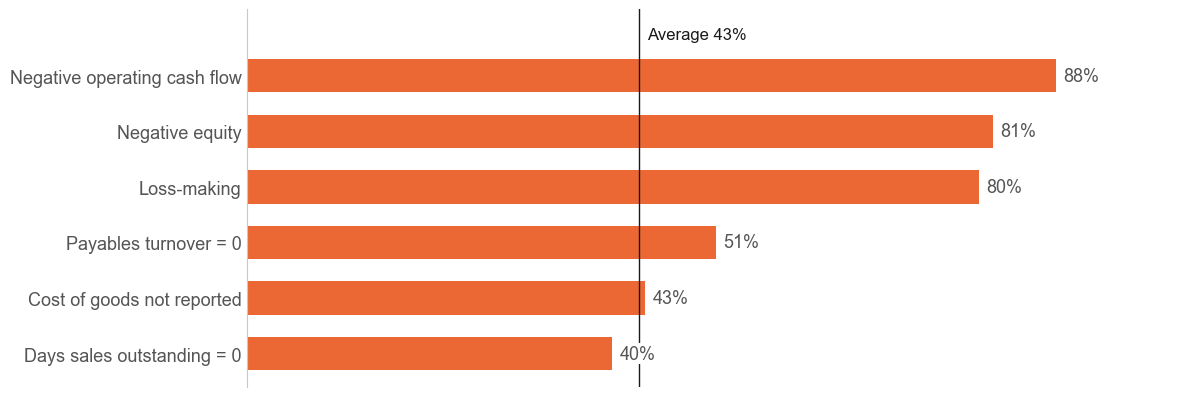

In [12]:
SLIDES.mkdir(parents=True, exist_ok=True)
SG_C, INK, INK2 = "#eb6834", "#1a1a1a", "#555555"                # the deck style of 01, section 15
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 14,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.spines.bottom": False, "axes.edgecolor": "#c8c8c8",
                     "ytick.color": INK2, "ytick.labelsize": 13, "text.color": INK, "figure.facecolor": "white",
                     "savefig.facecolor": "white", "savefig.dpi": 200})
FLAG_LABELS = {"ocf_negative": "Negative operating cash flow", "negative_equity": "Negative equity", "roe_negative": "Loss-making",
               "payables_zero": "Payables turnover = 0", "cogs_not_reported": "Cost of goods not reported",
               "dso_zero": "Days sales outstanding = 0"}
share = pd.Series({f: X.SG[X[f] == 1].mean() * 100 for f in FLAGS}).sort_values()
base = X.SG.mean() * 100

fig, ax = plt.subplots(figsize=(12, 4.2))
y = np.arange(len(share))
ax.barh(y, share, height=0.6, color=SG_C)
for yi, v in zip(y, share):
    ax.text(v + 0.8, yi, f"{v:.0f}%", va="center", fontsize=13, color=INK2, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(base, color=INK, lw=1)
ax.text(base + 0.8, len(share) - 0.4, f"Average {base:.0f}%", fontsize=12, va="bottom")
ax.set_yticks(y, [FLAG_LABELS[f] for f in share.index])
ax.tick_params(axis="y", length=0)
ax.set(xlim=(0, 100), xticks=[], ylim=(-0.6, len(share) + 0.2))
fig.tight_layout()
fig.savefig(SLIDES / "flags.png")
plt.show()

## 7. Figure for the presentation: how each ratio was repaired
One bar per ratio that a rule changed: the number of firm-years affected (of 2,028) and what was done. Rebuilt values, a dropped column,
impossible values blanked, misleading values blanked and flagged. Every remaining blank is filled with the training median inside the model (03).

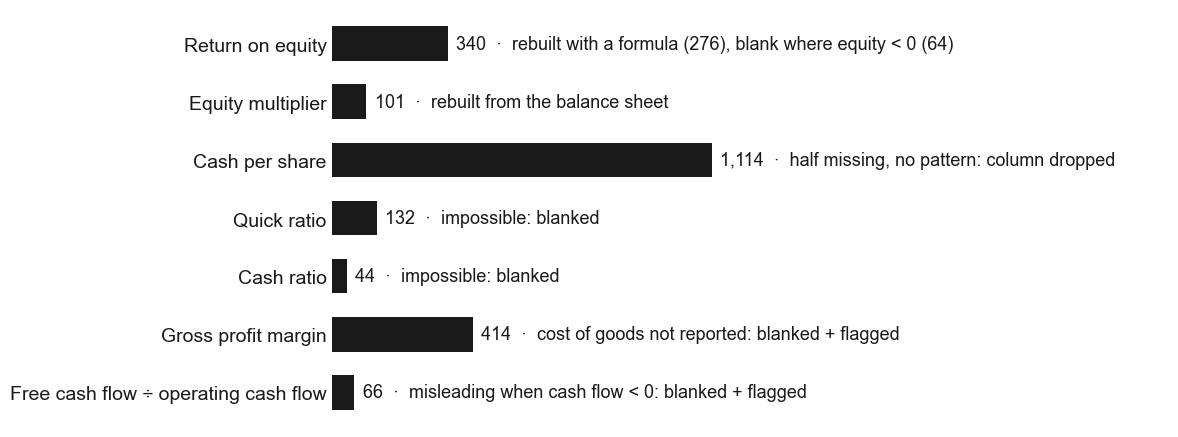

In [13]:
LABELS = {"returnOnEquity": "Return on equity", "companyEquityMultiplier": "Equity multiplier", "cashPerShare": "Cash per share",
          "quickRatio": "Quick ratio", "cashRatio": "Cash ratio", "grossProfitMargin": "Gross profit margin",
          "freeCashFlowOperatingCashFlowRatio": "Free cash flow ÷ operating cash flow"}
roe = REPAIRS["returnOnEquity"]
ACTION = {"returnOnEquity": f"rebuilt with a formula ({roe['rebuilt']}), blank where equity < 0 ({roe['left_blank']})",
          "companyEquityMultiplier": "rebuilt from the balance sheet", "cashPerShare": "half missing, no pattern: column dropped",
          "quickRatio": "impossible: blanked", "cashRatio": "impossible: blanked",
          "grossProfitMargin": "cost of goods not reported: blanked + flagged",
          "freeCashFlowOperatingCashFlowRatio": "misleading when cash flow < 0: blanked + flagged"}
order = list(LABELS)                                                         # grouped by what was done, top to bottom
rows = [REPAIRS[k]["rows"] for k in order]
fig, ax = plt.subplots(figsize=(12, 4.6))
y = np.arange(len(order))[::-1]
ax.barh(y, rows, height=0.6, color=INK)
for yi, k, n in zip(y, order, rows):
    ax.text(n + 25, yi, f"{n:,}  ·  {ACTION[k]}", va="center", fontsize=13)
ax.set_yticks(y, [LABELS[k] for k in order])
ax.tick_params(axis="y", length=0, labelsize=14, labelcolor=INK)
ax.set(xlim=(0, 2450), xticks=[], ylim=(-0.6, len(order) - 0.4))
ax.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig(SLIDES / "ratio_repairs.png")
plt.show()

## 8. Figure for the presentation: misleading values
Left: gross margin as delivered; a fifth of firm-years sit at 99% or more, mostly in Energy and Public Utilities, where cost of goods
is often not reported separately. Right: free cash flow ÷ operating cash flow is above 1 far more often when operating cash flow is negative,
because two negatives make a positive. Both are blanked and flagged (section 2).

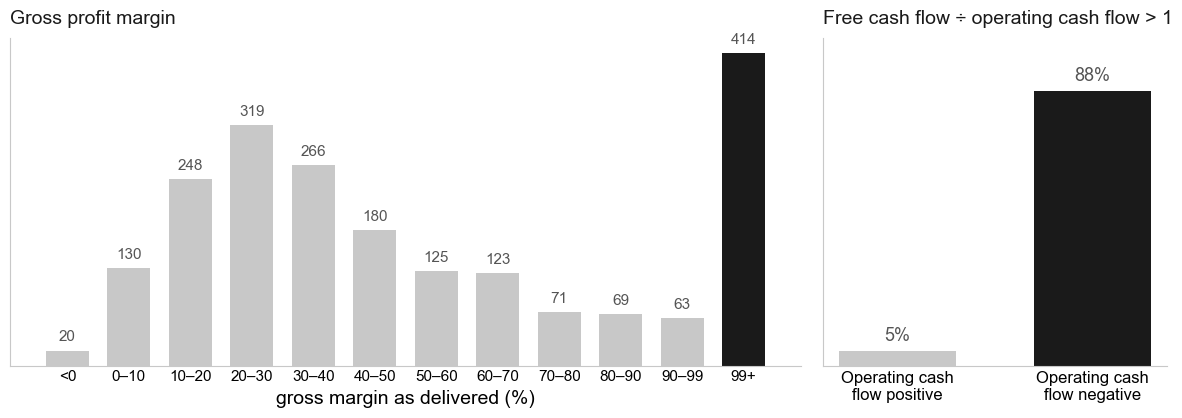

In [14]:
GRAY, BLACK = "#c8c8c8", INK                                       # gray = context, black = values a rule touches
gm = src.grossProfitMargin
edges = [-np.inf, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.99, np.inf]
counts = pd.cut(gm, edges, right=False).value_counts(sort=False).to_numpy()
labels = ["<0", "0–10", "10–20", "20–30", "30–40", "40–50", "50–60", "60–70", "70–80", "80–90", "90–99", "99+"]
neg_ocf = src.operatingCashFlowSalesRatio < 0
above_one = [(src.freeCashFlowOperatingCashFlowRatio[~neg_ocf] > 1).mean() * 100,
             (src.freeCashFlowOperatingCashFlowRatio[neg_ocf] > 1).mean() * 100]
assert counts[-1] == NUMBERS["repairs"]["grossProfitMargin"]["rows"] and neg_ocf.sum() == NUMBERS["repairs"]["freeCashFlowOperatingCashFlowRatio"]["rows"]
NUMBERS.update(misleading={"gross_margin_99_plus": int(counts[-1]),
                           "gross_margin_99_plus_by_sector": src.Sector[gm >= 0.99].value_counts().head(3).to_dict(),
                           "fcf_ocf_above_1_share_ocf_positive": round(above_one[0] / 100, 3),
                           "fcf_ocf_above_1_share_ocf_negative": round(above_one[1] / 100, 3)})
_ = (RES / "cleaning_numbers.json").write_text(json.dumps(NUMBERS, indent=1, default=int))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [2.3, 1]})
a1.bar(range(len(counts)), counts, width=0.7, color=[GRAY] * (len(counts) - 1) + [BLACK])
for xi, v in enumerate(counts):
    a1.text(xi, v + 8, f"{v:,}", ha="center", va="bottom", fontsize=11, color=INK2)
a1.set_xticks(range(len(counts)), labels, fontsize=11)
a1.set(yticks=[], xlabel="gross margin as delivered (%)")
a1.set_title("Gross profit margin", loc="left", fontsize=14, pad=10)
a2.bar([0, 1], above_one, width=0.6, color=[GRAY, BLACK])
for xi, v in enumerate(above_one):
    a2.text(xi, v + 2, f"{v:.0f}%", ha="center", va="bottom", fontsize=13, color=INK2)
a2.set_xticks([0, 1], ["Operating cash\nflow positive", "Operating cash\nflow negative"], fontsize=12)
a2.set(yticks=[], ylim=(0, 105))
a2.set_title("Free cash flow ÷ operating cash flow > 1", loc="left", fontsize=14, pad=10)
for ax in (a1, a2):
    ax.tick_params(axis="x", length=0)
    ax.spines["bottom"].set_visible(True)
fig.tight_layout()
fig.savefig(SLIDES / "misleading_values.png")
plt.show()